# Customer retention decision support

This walkthrough uses a seeded synthetic churn dataset. Full mode separately downloads UCI Iranian Churn locally and publishes aggregate evaluation results in artifacts/full. No demo observation represents a real person. Built with AI assistance.

In [1]:
import json
from pathlib import Path

import pandas as pd

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
RUN = ROOT / "artifacts/demo"
print("Retail and churn mode: seeded synthetic offline demo. Logistics: synthetic.")

Retail and churn mode: seeded synthetic offline demo. Logistics: synthetic.


In [2]:
from portfolio.churn import FEATURES, grouped_split, prepare_churn
from portfolio.synthetic import churn_demo

frame = prepare_churn(churn_demo())
train, validation, test, groups = grouped_split(frame)
print(
    {
        "rows": len(frame),
        "train": len(train),
        "validation": len(validation),
        "test": len(test),
        "prevalence": frame.churn.mean(),
    }
)
assert set(groups.iloc[train]).isdisjoint(groups.iloc[test])
assert set(groups.iloc[validation]).isdisjoint(groups.iloc[test])
print("Predictors:", FEATURES)

{'rows': 1500, 'train': 900, 'validation': 300, 'test': 300, 'prevalence': np.float64(0.21533333333333332)}
Predictors: ['call_failure', 'complains', 'subscription_length', 'charge_amount', 'seconds_of_use', 'frequency_of_use', 'frequency_of_sms', 'distinct_called_numbers', 'tariff_plan']


## 1. Review baseline comparison

The build fits dummy prior, logistic regression and random forest models on training only. Validation average precision chooses the model. Status, Customer Value and demographic fields are excluded.

In [3]:
comparison = pd.read_csv(RUN / "churn_model_comparison.csv")
comparison

,model,average_precision,roc_auc,brier_score,precision,recall,threshold
0,dummy_prior,0.216667,0.500000,0.169727,0.00000,0.000000,0.5
1,logistic_regression,0.547331,0.710442,0.132030,0.74359,0.446154,0.5
2,random_forest,0.540926,0.698658,0.135136,0.72973,0.415385,0.5


## 2. Inspect the frozen-model test results

The threshold is selected on validation under arbitrary 5:1 error weights. It is not a measured treatment cost. Test labels do not select the model or threshold. No refit on validation occurs.

In [4]:
summary = json.loads((RUN / "churn_summary.json").read_text())
pd.Series(summary["test_metrics"])

average_precision                 0.605908
roc_auc                           0.741997
brier_score                        0.12827
precision                         0.710526
recall                            0.415385
confusion_matrix     [[224, 11], [38, 27]]
threshold                             0.53
dtype: object

In [5]:
import math

scored = pd.read_csv(RUN / "churn_test_predictions.csv").sort_values(
    "risk_probability", ascending=False
)

queue = scored.head(math.ceil(len(scored) * 0.2))
print(
    {
        "review_slots": len(queue),
        "observed_precision": queue.churn.mean(),
        "test_prevalence": scored.churn.mean(),
        "observed_lift": queue.churn.mean() / scored.churn.mean(),
    }
)

{'review_slots': 60, 'observed_precision': np.float64(0.5333333333333333), 'test_prevalence': np.float64(0.21666666666666667), 'observed_lift': np.float64(2.4615384615384612)}


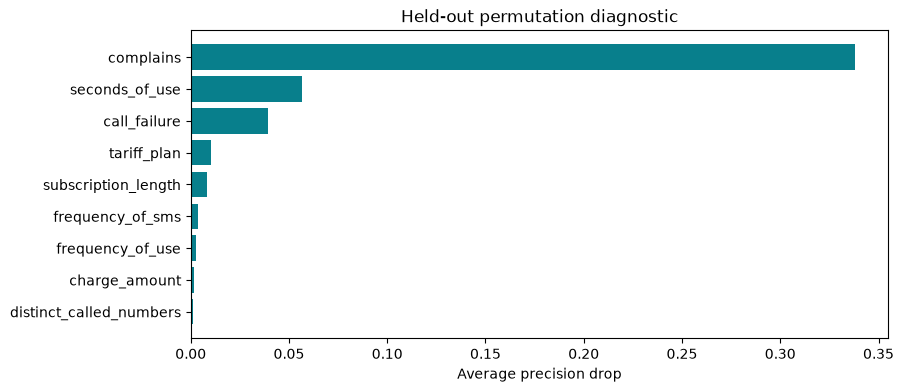

In [6]:
import matplotlib.pyplot as plt

importance = pd.read_csv(RUN / "churn_importance.csv").sort_values("ap_drop_mean")
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(importance.feature, importance.ap_drop_mean, color="#087f8c")
ax.set(title="Held-out permutation diagnostic", xlabel="Average precision drop")
plt.show()

## 3. Interpretation and next action

Permutation importance is association, not causation. Correlated features share information. Predicted churn is not treatment uplift. Data lacks true timestamps and account IDs, so temporal validation and full identity separation remain unavailable. Obtain new local data, calibrate prospectively, evaluate subgroups and run a randomised retention pilot before deployment.